<a href="https://colab.research.google.com/github/saadbinather/titanic-stats/blob/main/R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
install.packages("MASS")
library(MASS)

data("Boston")
df <- Boston

head(df)
dim(df)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,black,lstat,medv
,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0.00632,18,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
2,0.02731,0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
3,0.02729,0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
4,0.03237,0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
5,0.06905,0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
6,0.02985,0,2.18,0,0.458,6.430,58.7,6.0622,3,222,18.7,394.12,5.21,28.7


[1] 506  14

In [ ]:
dim(df)
names(df)
summary(df)

[1] 506  14

[1] "crim"    "zn"      "indus"   "chas"    "nox"     "rm"      "age"    
 [8] "dis"     "rad"     "tax"     "ptratio" "black"   "lstat"   "medv"

      crim                zn             indus            chas        
 Min.   : 0.00632   Min.   :  0.00   Min.   : 0.46   Min.   :0.00000  
 1st Qu.: 0.08205   1st Qu.:  0.00   1st Qu.: 5.19   1st Qu.:0.00000  
 Median : 0.25651   Median :  0.00   Median : 9.69   Median :0.00000  
 Mean   : 3.61352   Mean   : 11.36   Mean   :11.14   Mean   :0.06917  
 3rd Qu.: 3.67708   3rd Qu.: 12.50   3rd Qu.:18.10   3rd Qu.:0.00000  
 Max.   :88.97620   Max.   :100.00   Max.   :27.74   Max.   :1.00000  
      nox               rm             age              dis        
 Min.   :0.3850   Min.   :3.561   Min.   :  2.90   Min.   : 1.130  
 1st Qu.:0.4490   1st Qu.:5.886   1st Qu.: 45.02   1st Qu.: 2.100  
 Median :0.5380   Median :6.208   Median : 77.50   Median : 3.207  
 Mean   :0.5547   Mean   :6.285   Mean   : 68.57   Mean   : 3.795  
 3rd Qu.:0.6240   3rd Qu.:6.623   3rd Qu.: 94.08   3rd Qu.: 5.188  
 Max.   :0.8710   Max.   :8.780   Max.   :100.00   Max.   :12.127  
      rad              tax 

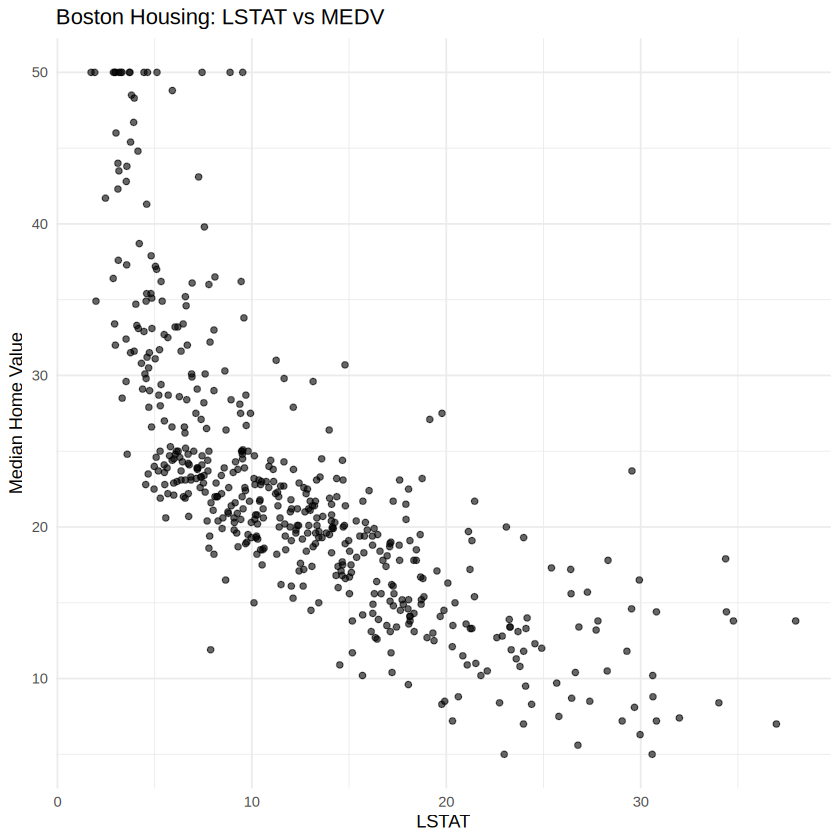

In [ ]:
library(ggplot2)

ggplot(df, aes(x = lstat, y = medv)) +
  geom_point(alpha = 0.6) +
  theme_minimal() +
  labs(
    title = "Boston Housing: LSTAT vs MEDV",
    x = "LSTAT",
    y = "Median Home Value"
  )

In [ ]:
model1 <- lm(medv ~ lstat, data = df)

summary(model1)


Call:
lm(formula = medv ~ lstat, data = df)

Residuals:
    Min      1Q  Median      3Q     Max 
-15.168  -3.990  -1.318   2.034  24.500 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 34.55384    0.56263   61.41   <2e-16 ***
lstat       -0.95005    0.03873  -24.53   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 6.216 on 504 degrees of freedom
Multiple R-squared:  0.5441,	Adjusted R-squared:  0.5432 
F-statistic: 601.6 on 1 and 504 DF,  p-value: < 2.2e-16


`geom_smooth()` using formula = 'y ~ x'


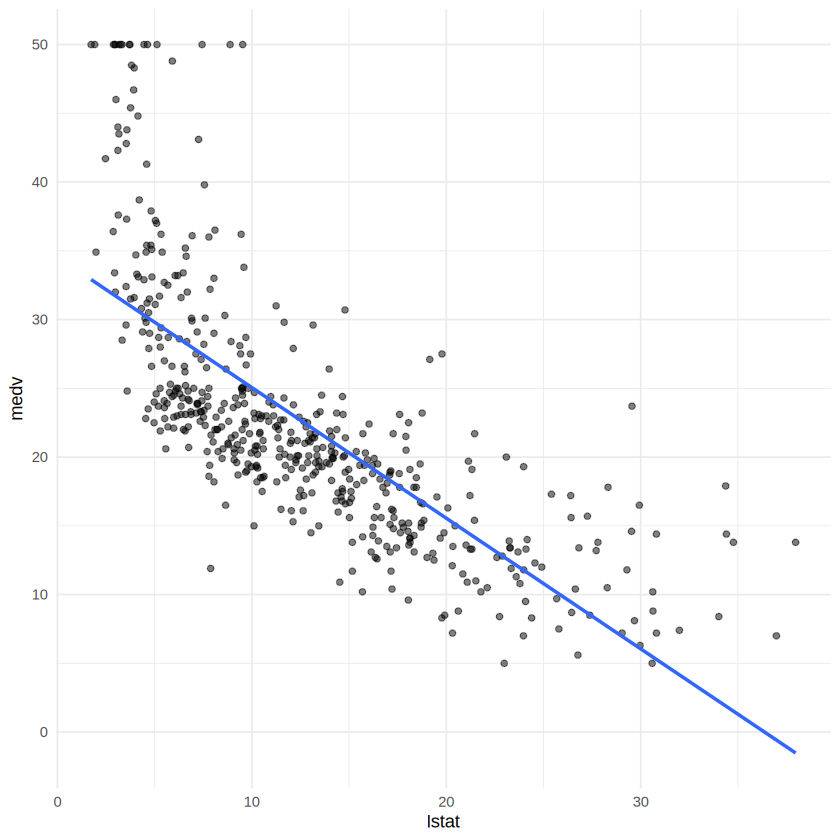

In [ ]:
ggplot(df, aes(x = lstat, y = medv)) +
  geom_point(alpha = 0.5) +
  geom_smooth(method = "lm", se = FALSE) +
  theme_minimal()

In [ ]:
set.seed(42)

idx <- sample(1:nrow(df), 0.7 * nrow(df))

train <- df[idx, ]
test  <- df[-idx, ]

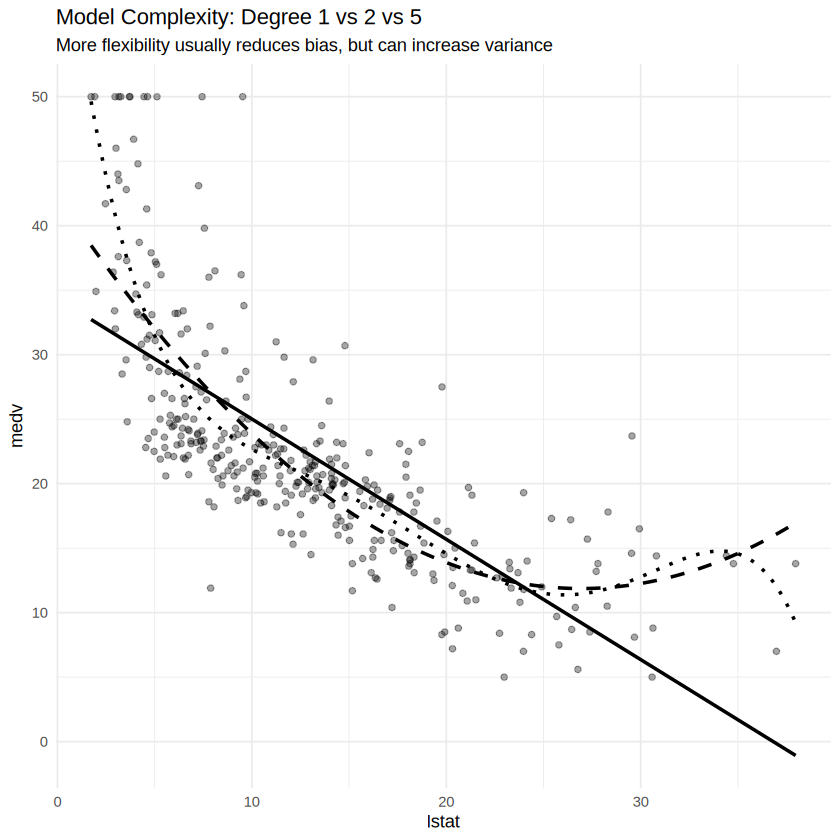

In [ ]:
m1 <- lm(medv ~ poly(lstat, 1, raw = TRUE), data = train)
m2 <- lm(medv ~ poly(lstat, 2, raw = TRUE), data = train)
m5 <- lm(medv ~ poly(lstat, 5, raw = TRUE), data = train)

grid <- data.frame(
  lstat = seq(min(df$lstat), max(df$lstat), length.out = 300)
)

grid$p1 <- predict(m1, grid)
grid$p2 <- predict(m2, grid)
grid$p5 <- predict(m5, grid)

ggplot(train, aes(lstat, medv)) +
  geom_point(alpha = 0.35) +
  geom_line(data = grid, aes(lstat, p1), linewidth = 1) +
  geom_line(data = grid, aes(lstat, p2), linetype = 2, linewidth = 1) +
  geom_line(data = grid, aes(lstat, p5), linetype = 3, linewidth = 1) +
  theme_minimal() +
  labs(
    title = "Model Complexity: Degree 1 vs 2 vs 5",
    subtitle = "More flexibility usually reduces bias, but can increase variance"
  )

In [ ]:
degrees <- 1:12

train_mse <- numeric(length(degrees))
test_mse <- numeric(length(degrees))

for(d in degrees){

  model <- lm(
    medv ~ poly(lstat, d, raw = TRUE),
    data = train
  )

  pred_train <- predict(model, train)
  pred_test <- predict(model, test)

  train_mse[d] <- mean((train$medv - pred_train)^2)
  test_mse[d] <- mean((test$medv - pred_test)^2)
}

error_df <- data.frame(
  degree = degrees,
  train = train_mse,
  test = test_mse
)

error_df

degree,train,test
<int>,<dbl>,<dbl>
1,38.51848,38.45211
2,30.89190,29.16179
3,29.74801,27.13871
4,28.60525,25.56516
5,27.43680,26.18860
6,27.41059,25.99886
7,27.28653,26.40836
8,27.25769,26.17871
9,27.05554,26.25228


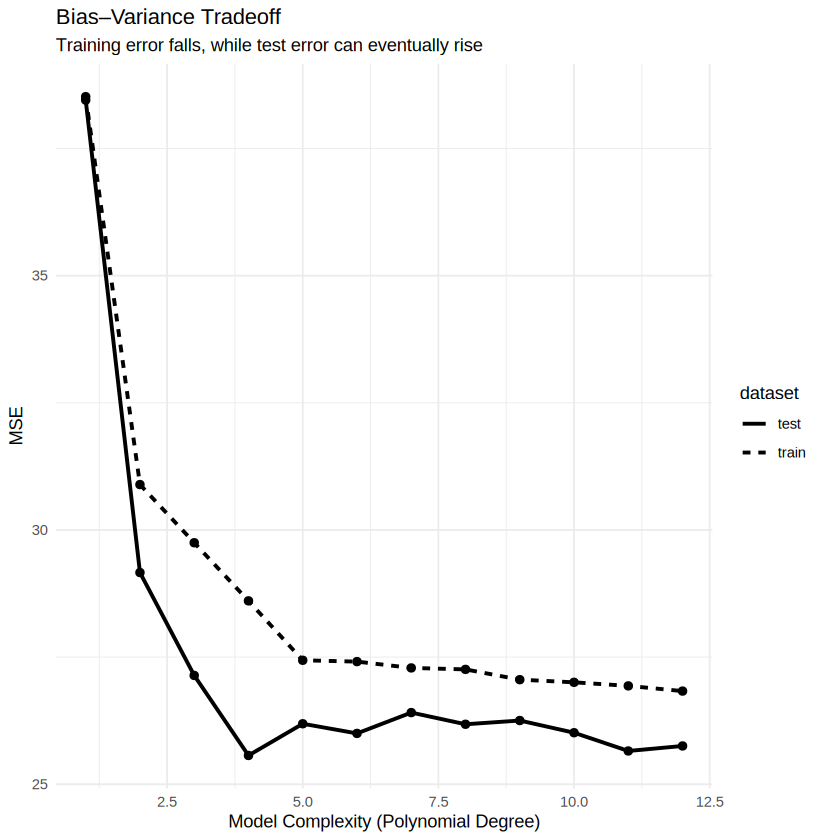

In [ ]:
library(tidyr)

error_long <- pivot_longer(
  error_df,
  cols = c(train, test),
  names_to = "dataset",
  values_to = "MSE"
)

ggplot(error_long,
       aes(degree, MSE, linetype = dataset)) +
  geom_line(linewidth = 1.1) +
  geom_point(size = 2) +
  theme_minimal() +
  labs(
    title = "Bias–Variance Tradeoff",
    subtitle = "Training error falls, while test error can eventually rise",
    x = "Model Complexity (Polynomial Degree)"
  )

In [ ]:
set.seed(42)

B <- 500
x0 <- data.frame(lstat = 15)

pred_deg1 <- numeric(B)
pred_deg2 <- numeric(B)
pred_deg10 <- numeric(B)

for(b in 1:B){

  boot_idx <- sample(
    1:nrow(df),
    replace = TRUE
  )

  boot <- df[boot_idx, ]

  pred_deg1[b] <- predict(
    lm(medv ~ poly(lstat, 1, raw = TRUE), data = boot),
    x0
  )

  pred_deg2[b] <- predict(
    lm(medv ~ poly(lstat, 2, raw = TRUE), data = boot),
    x0
  )

  pred_deg10[b] <- predict(
    lm(medv ~ poly(lstat, 10, raw = TRUE), data = boot),
    x0
  )
}

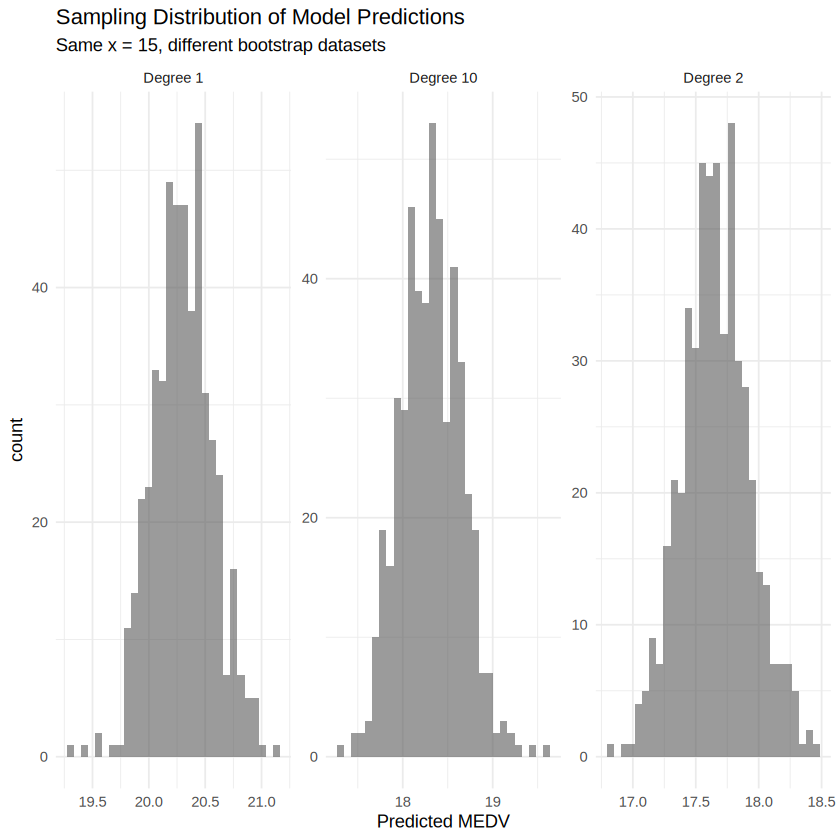

In [ ]:
pred_df <- data.frame(
  prediction = c(pred_deg1, pred_deg2, pred_deg10),
  model = factor(
    rep(c("Degree 1", "Degree 2", "Degree 10"),
        each = B)
  )
)

ggplot(pred_df, aes(prediction)) +
  geom_histogram(bins = 30, alpha = 0.6) +
  facet_wrap(~model, scales = "free") +
  theme_minimal() +
  labs(
    title = "Sampling Distribution of Model Predictions",
    subtitle = "Same x = 15, different bootstrap datasets",
    x = "Predicted MEDV"
  )

In [ ]:
data.frame(
  Model = c("Degree 1", "Degree 2", "Degree 10"),
  Mean_Prediction = c(
    mean(pred_deg1),
    mean(pred_deg2),
    mean(pred_deg10)
  ),
  Variance = c(
    var(pred_deg1),
    var(pred_deg2),
    var(pred_deg10)
  )
)

Model,Mean_Prediction,Variance
<chr>,<dbl>,<dbl>
Degree 1,20.30140,0.07139698
Degree 2,17.66125,0.07278867
Degree 10,18.31408,0.11495230


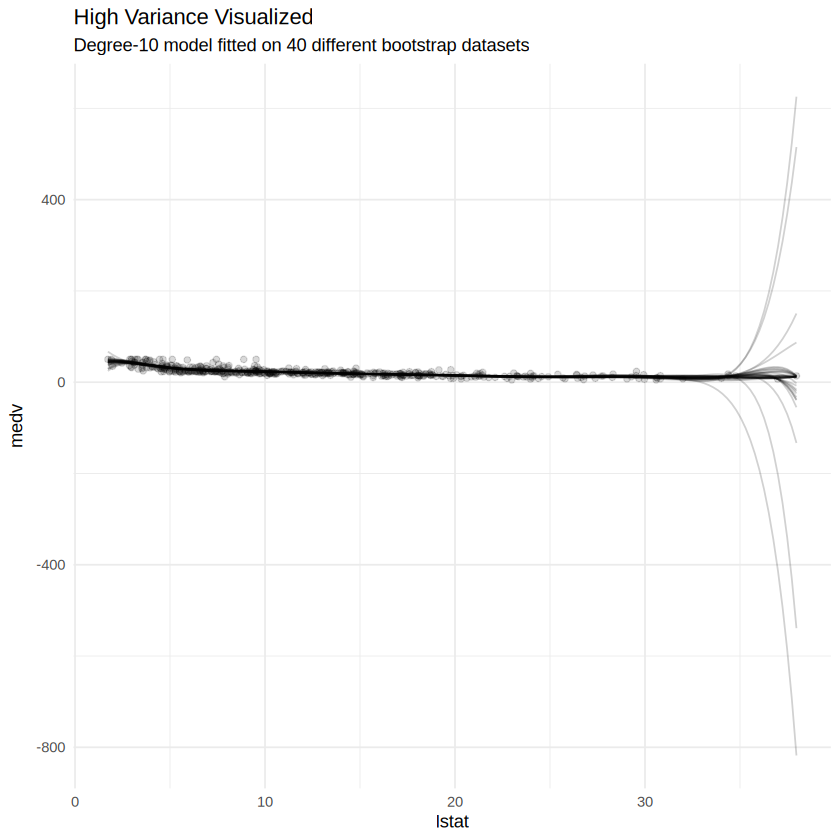

In [ ]:
set.seed(42)

x_grid <- seq(
  min(df$lstat),
  max(df$lstat),
  length.out = 150
)

curve_df <- data.frame()

for(b in 1:40){

  boot <- df[
    sample(1:nrow(df), replace = TRUE),
  ]

  model <- lm(
    medv ~ poly(lstat, 10, raw = TRUE),
    data = boot
  )

  preds <- predict(
    model,
    newdata = data.frame(lstat = x_grid)
  )

  temp <- data.frame(
    lstat = x_grid,
    prediction = preds,
    run = b
  )

  curve_df <- rbind(curve_df, temp)
}

ggplot(df, aes(lstat, medv)) +
  geom_point(alpha = 0.15) +
  geom_line(
    data = curve_df,
    aes(lstat, prediction, group = run),
    alpha = 0.18
  ) +
  theme_minimal() +
  labs(
    title = "High Variance Visualized",
    subtitle = "Degree-10 model fitted on 40 different bootstrap datasets"
  )

In [ ]:
set.seed(42)

library(splines)

# Reference approximation of underlying relationship
reference_model <- lm(
  medv ~ ns(lstat, df = 8),
  data = df
)

x_grid <- seq(
  quantile(df$lstat, 0.05),
  quantile(df$lstat, 0.95),
  length.out = 100
)

reference_truth <- predict(
  reference_model,
  newdata = data.frame(lstat = x_grid)
)

degrees <- 1:10
B <- 300

bias2 <- numeric(length(degrees))
variance <- numeric(length(degrees))
total_error <- numeric(length(degrees))

for(d in degrees){

  preds <- matrix(
    NA,
    nrow = B,
    ncol = length(x_grid)
  )

  for(b in 1:B){

    boot <- df[
      sample(1:nrow(df), replace = TRUE),
    ]

    model <- lm(
      medv ~ poly(lstat, d, raw = TRUE),
      data = boot
    )

    preds[b, ] <- predict(
      model,
      newdata = data.frame(lstat = x_grid)
    )
  }

  # Average prediction across datasets
  mean_pred <- colMeans(preds)

  # Bias²
  bias2[d] <- mean(
    (mean_pred - reference_truth)^2
  )

  # Variance
  variance[d] <- mean(
    apply(preds, 2, var)
  )

  # Bias² + Variance
  total_error[d] <- bias2[d] + variance[d]
}

In [ ]:
tradeoff <- data.frame(
  Complexity = degrees,
  Bias2 = bias2,
  Variance = variance,
  Total = total_error
)

round(tradeoff, 3)

Complexity,Bias2,Variance,Total
<dbl>,<dbl>,<dbl>,<dbl>
1,3.831,0.179,4.010
2,1.465,0.132,1.597
3,1.352,0.159,1.511
4,0.696,0.207,0.902
5,0.219,0.204,0.423
6,0.086,0.209,0.295
7,0.097,0.276,0.373
8,0.109,0.295,0.405
9,0.141,0.323,0.465


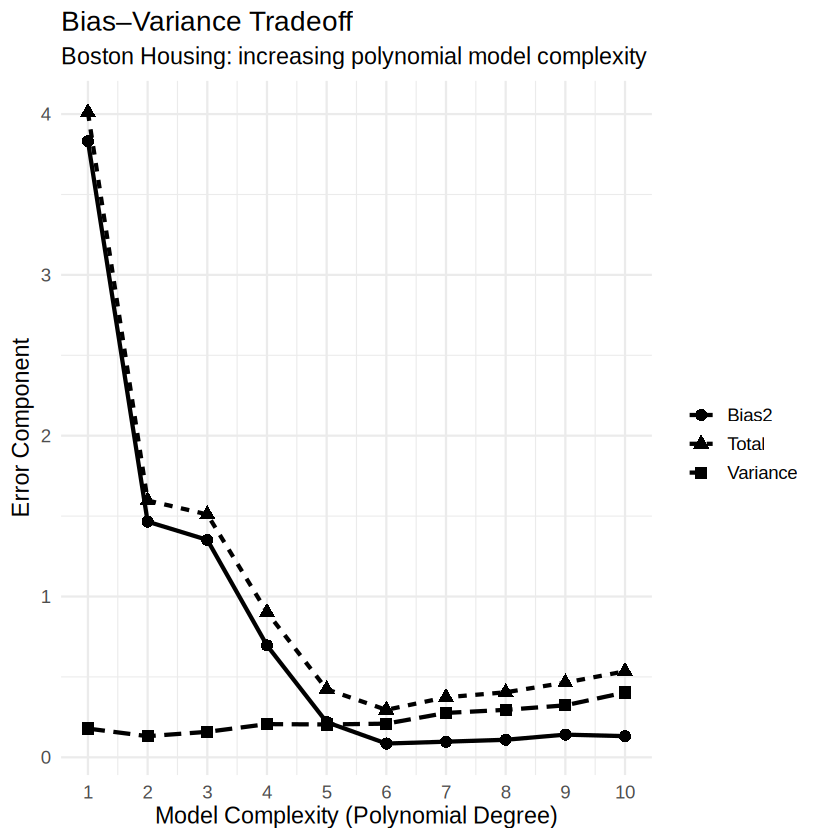

In [ ]:
library(tidyr)
library(ggplot2)

tradeoff_long <- pivot_longer(
  tradeoff,
  cols = c(Bias2, Variance, Total),
  names_to = "Component",
  values_to = "Error"
)

ggplot(
  tradeoff_long,
  aes(
    x = Complexity,
    y = Error,
    linetype = Component,
    shape = Component
  )
) +
  geom_line(linewidth = 1.2) +
  geom_point(size = 3) +
  scale_x_continuous(breaks = degrees) +
  theme_minimal(base_size = 14) +
  labs(
    title = "Bias–Variance Tradeoff",
    subtitle = "Boston Housing: increasing polynomial model complexity",
    x = "Model Complexity (Polynomial Degree)",
    y = "Error Component",
    linetype = "",
    shape = ""
  )

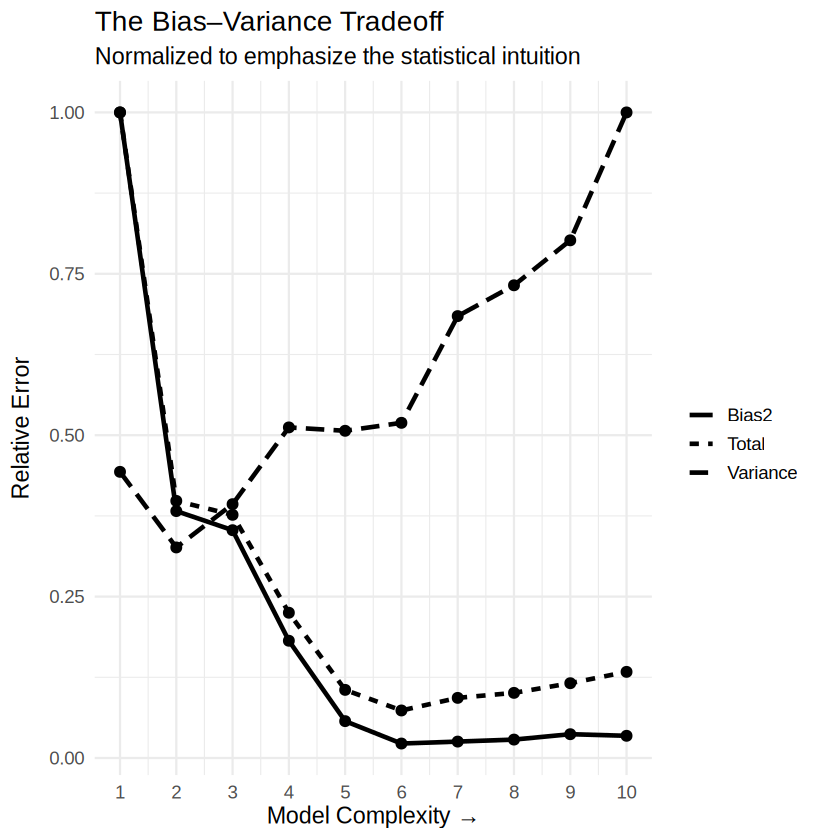

In [ ]:
tradeoff_norm <- tradeoff

tradeoff_norm$Bias2 <-
  tradeoff$Bias2 / max(tradeoff$Bias2)

tradeoff_norm$Variance <-
  tradeoff$Variance / max(tradeoff$Variance)

tradeoff_norm$Total <-
  tradeoff$Total / max(tradeoff$Total)

tradeoff_norm_long <- pivot_longer(
  tradeoff_norm,
  cols = c(Bias2, Variance, Total),
  names_to = "Component",
  values_to = "Relative_Error"
)

ggplot(
  tradeoff_norm_long,
  aes(
    Complexity,
    Relative_Error,
    linetype = Component
  )
) +
  geom_line(linewidth = 1.3) +
  geom_point(size = 2.5) +
  scale_x_continuous(breaks = degrees) +
  theme_minimal(base_size = 14) +
  labs(
    title = "The Bias–Variance Tradeoff",
    subtitle = "Normalized to emphasize the statistical intuition",
    x = "Model Complexity →",
    y = "Relative Error",
    linetype = ""
  )